# **Thresholding and binarization**

#### **1. What is thresholding?**
Thresholding is a fundamental image processing technique to convert grayscale images into binary images (black and white). This is useful for segmenting objects from a background, such as text from paper, coins on a surface, or cells under a microscope.

- Thresholding divides pixels into two groups based on intensity.
- A threshold value **T** is chosen.
- Pixels with intensity above **T** become white (1), below become black (0) or vice versa.
- Result: A binary image highlighting foreground objects.

In [5]:
from skimage import data
import matplotlib.pyplot as plt

text_image = data.text() 

print(text_image.shape)

(172, 448)


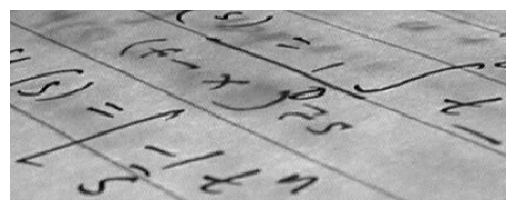

In [6]:

plt.imshow(text_image, cmap='gray')
plt.axis('off')
plt.show()

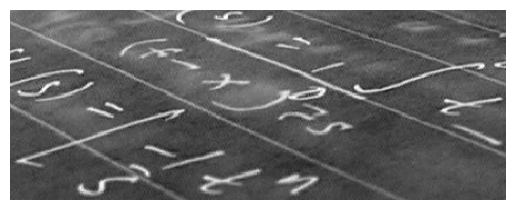

In [4]:
plt.imshow(text_image, cmap='gray_r')
plt.axis('off')
plt.show()

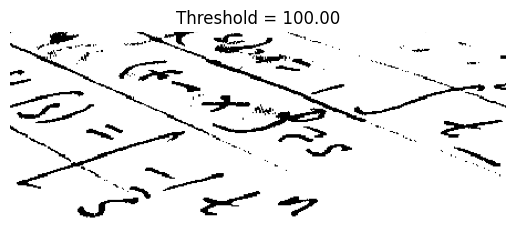

In [51]:

T = 100  # try also other values, e.g. 100, 150, 200

binary_140 = text_image > T 

plt.imshow(binary_140, cmap='gray')
plt.title(f"Threshold = {T:.2f}")
plt.axis('off')

plt.show()

#### **3. Global thresholding: Otsu’s method**

Otsu’s method automatically finds an optimal global threshold by minimizing intra-class variance (variance within foreground and background).

Best for images with bimodal histograms (foreground and background intensities clearly separate).

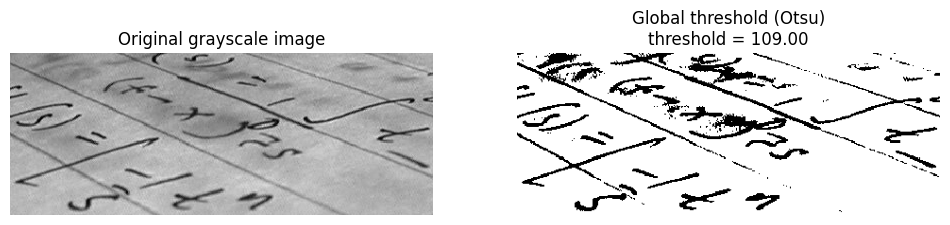

In [52]:
from skimage.filters import threshold_otsu

global_T = threshold_otsu(text_image)

binary_global = text_image > global_T # or <= for inverted

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(text_image, cmap='gray')
ax[0].set_title("Original grayscale image")
ax[0].axis('off')

ax[1].imshow(binary_global, cmap='gray')
ax[1].set_title(f"Global threshold (Otsu)\nthreshold = {global_T:.2f}")
ax[1].axis('off')

plt.show()


#### **4. Local (adaptive) thresholding**

Global thresholding can fail if lighting is uneven or background varies. Local thresholding computes threshold for each pixel based on its surrounding neighbors.Useful for complex lighting, shadows, or textures.


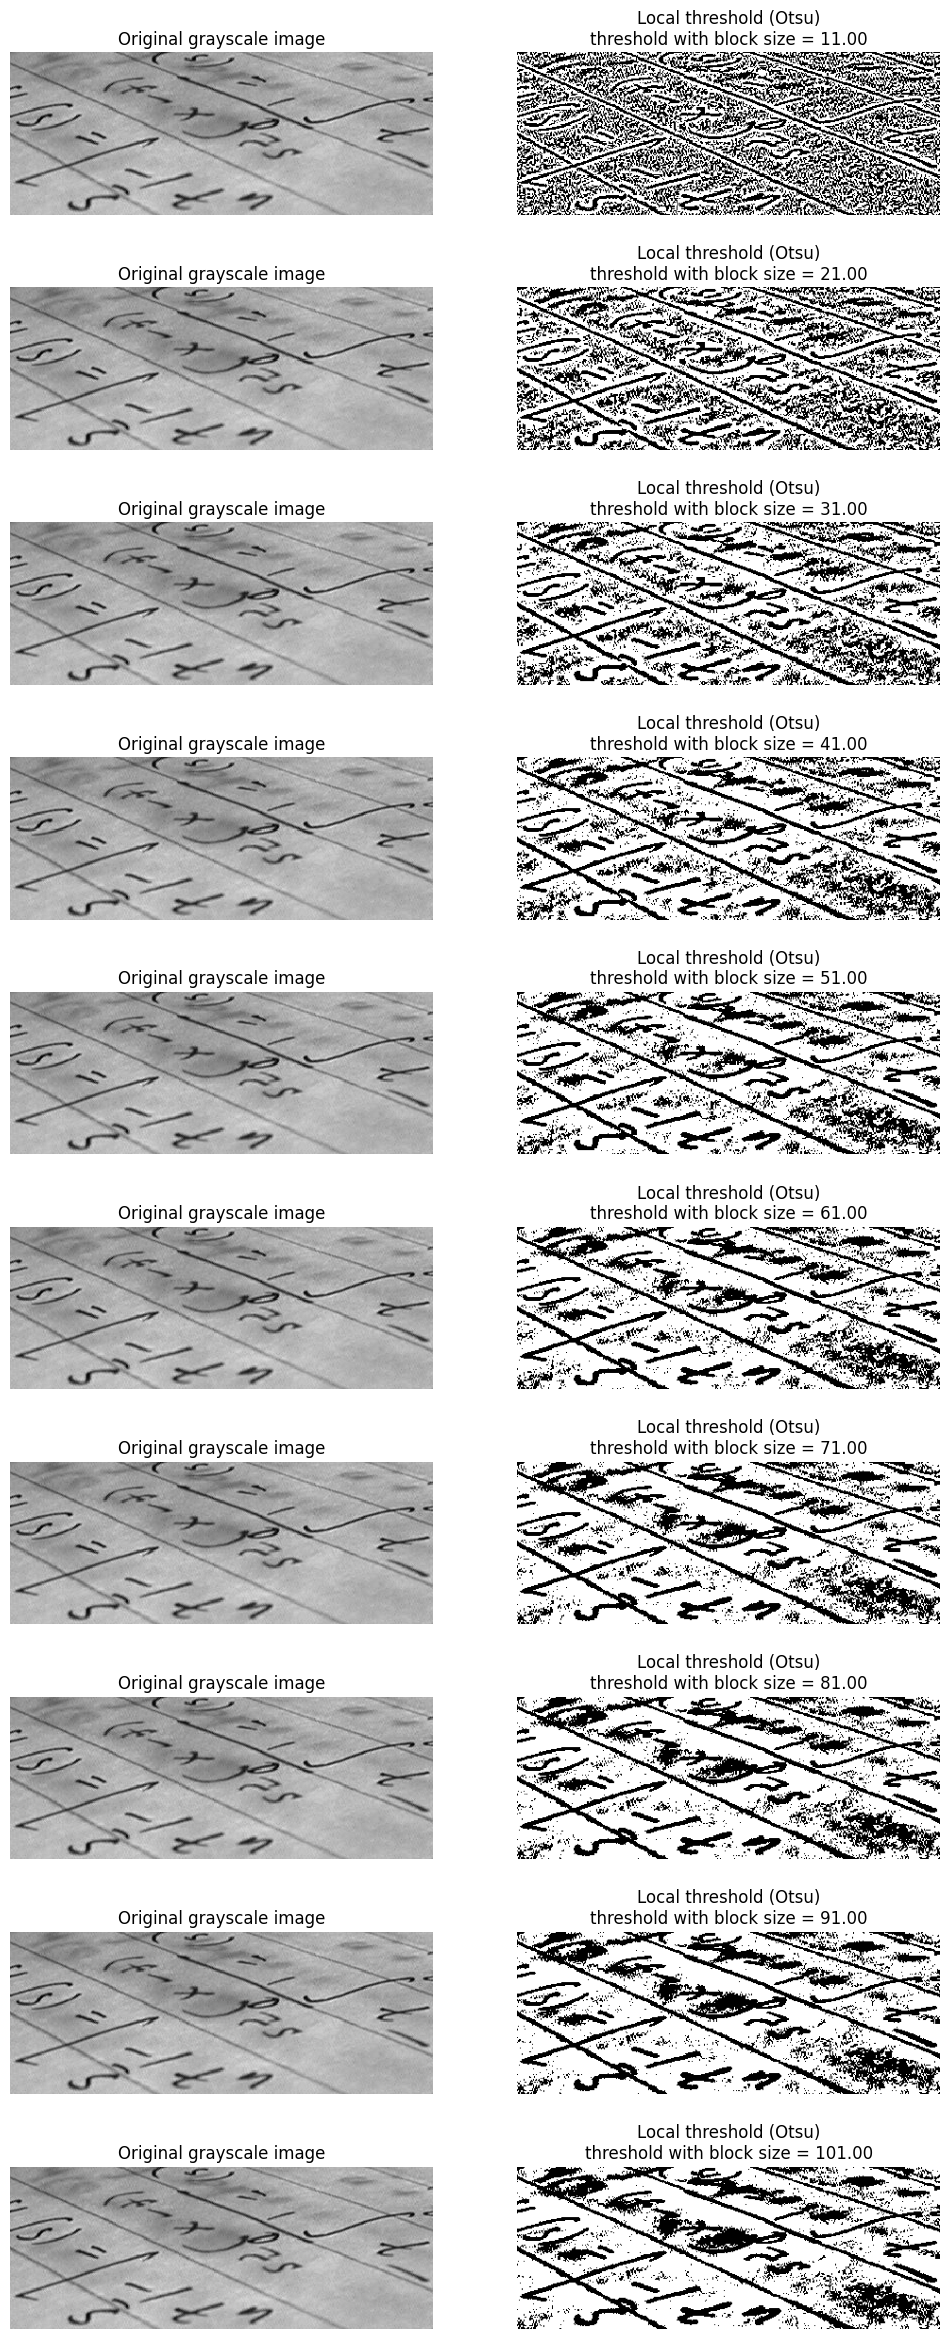

In [53]:
from skimage.filters import threshold_local

max_pic = 10

fig, ax = plt.subplots(max_pic, 2, figsize=(12, 3 * max_pic))

for i in range(max_pic):

    block_size = 11 + i * max_pic
    local_T = threshold_local(text_image, block_size)
    binary_local = text_image > local_T

    ax[i, 0].imshow(text_image, cmap='gray')
    ax[i, 0].set_title("Original grayscale image")
    ax[i, 0].axis('off')

    ax[i, 1].imshow(binary_local, cmap='gray')
    ax[i, 1].set_title("Local adaptive threshold")
    ax[i, 1].set_title(f"Local threshold (Otsu)\nthreshold with block size = {block_size:.2f}")
    ax[i, 1].axis('off')

plt.show()

#### **2. Inverting the binary image**
   
Sometimes foreground is black and background white. We can invert binary images by flipping zeros and ones.

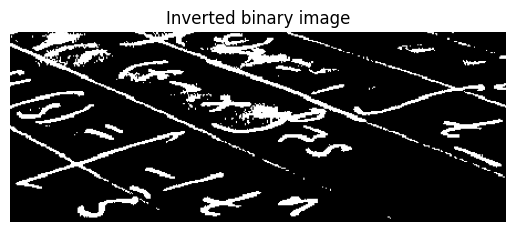

In [54]:
binary_inv = ~binary_global

plt.imshow(binary_inv, cmap='gray')
plt.title("Inverted binary image")
plt.axis('off')
plt.show()


Method using NumPy:

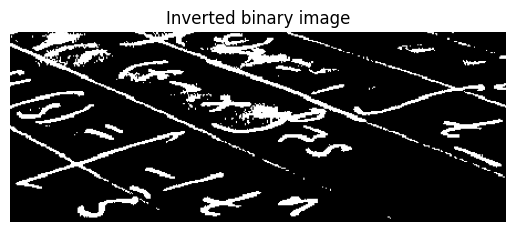

In [55]:
import numpy as np

binary_inv = np.invert(binary_global)

plt.imshow(binary_inv, cmap='gray')
plt.title("Inverted binary image")
plt.axis('off')
plt.show()

#### **5. Comparison of thresholding algorithms**

`try_all_threshold` allows visual comparison of multiple thresholding algorithms to choose the most suitable for your image.

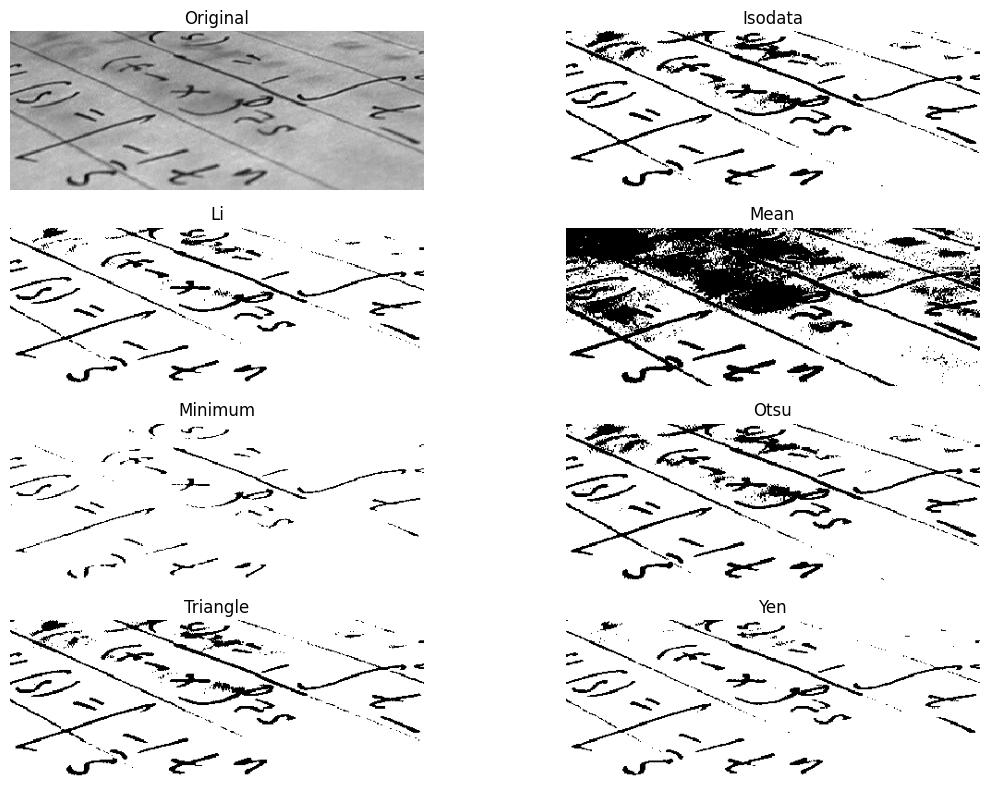

In [56]:
from skimage.filters import try_all_threshold

fig, ax = try_all_threshold(text_image, figsize=(12, 8), verbose=False)
plt.show()

#### **6. Multi-level thresholding**

Instead of dividing into two classes, multi-level thresholding separates pixels into multiple classes based on several thresholds. This is useful for images with multiple intensity classes (e.g., different tissues in medical imaging).

Thresholds: [ 90 129]


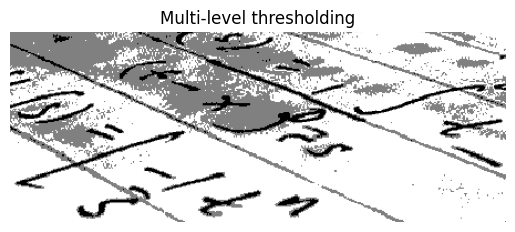

In [57]:
from skimage.filters import threshold_multiotsu

thresholds = threshold_multiotsu(text_image, classes=3)
print("Thresholds:", thresholds)
regions = np.digitize(text_image, bins=thresholds)

plt.imshow(regions, cmap='gray')
plt.title("Multi-level thresholding")
plt.axis('off')
plt.show()
